In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/nigeria_modeling_dataset.csv')

# Compute log transform of VIIRS radiance due to right-skewed urban distributions
df['log_viirs'] = np.log1p(df['viirs_mean_radiance'])

corr_viirs = df['log_viirs'].corr(df['poverty_rate_pct'])
corr_ndvi = df['modis_mean_ndvi'].corr(df['poverty_rate_pct'])

print(f"Correlation (log(VIIRS) vs. Poverty Rate): {corr_viirs:.3f}")
print(f"Correlation (MODIS NDVI vs. Poverty Rate): {corr_ndvi:.3f}")

Correlation (log(VIIRS) vs. Poverty Rate): -0.625
Correlation (MODIS NDVI vs. Poverty Rate): -0.738


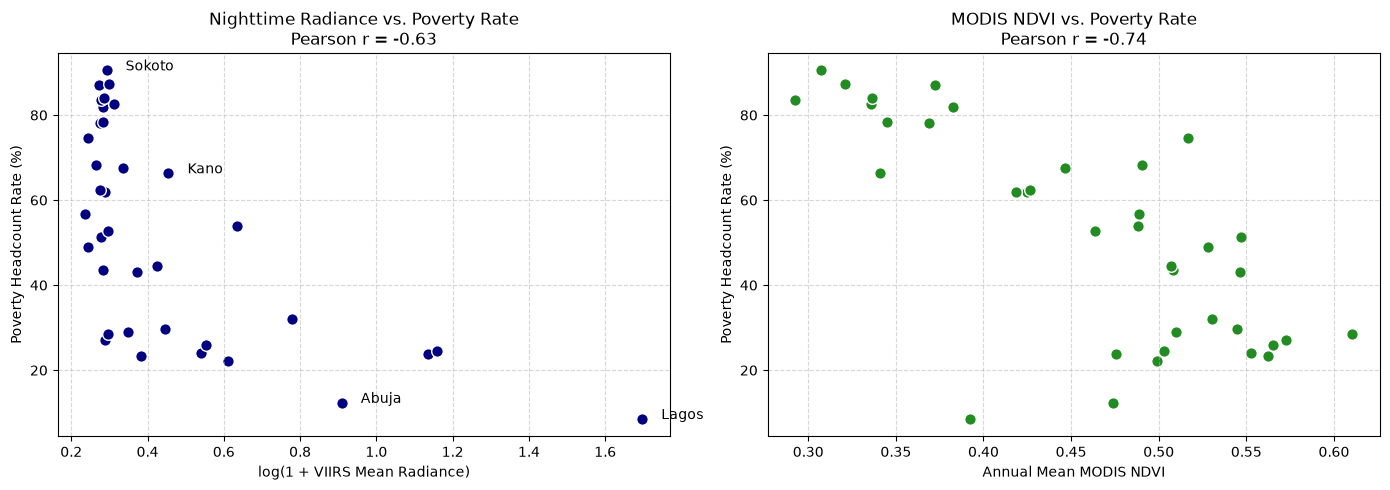

✓ Saved correlation plot to docs/feature_correlations.png


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Nighttime Radiance vs. Poverty
axes[0].scatter(df['log_viirs'], df['poverty_rate_pct'], color='navy', edgecolors='white', s=70)
axes[0].set_title(f"Nighttime Radiance vs. Poverty Rate\nPearson r = {corr_viirs:.2f}")
axes[0].set_xlabel("log(1 + VIIRS Mean Radiance)")
axes[0].set_ylabel("Poverty Headcount Rate (%)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Annotate outliers (e.g., Lagos, Abuja)
for _, row in df.iterrows():
    if row['state_name'] in ['Lagos', 'Abuja', 'Sokoto', 'Kano']:
        axes[0].annotate(row['state_name'], (row['log_viirs'] + 0.05, row['poverty_rate_pct']))

# 2. Vegetation Index vs. Poverty
axes[1].scatter(df['modis_mean_ndvi'], df['poverty_rate_pct'], color='forestgreen', edgecolors='white', s=70)
axes[1].set_title(f"MODIS NDVI vs. Poverty Rate\nPearson r = {corr_ndvi:.2f}")
axes[1].set_xlabel("Annual Mean MODIS NDVI")
axes[1].set_ylabel("Poverty Headcount Rate (%)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../docs/feature_correlations.png', dpi=300)
plt.show()
print("✓ Saved correlation plot to docs/feature_correlations.png")